# ConvNeXt-Tiny: full training run

Run this notebook in Kaggle with a GPU and Internet enabled. Reuse the existing
preprocessing, grouped train/validation split, loaders and validation helpers below.
The model/training sections are separated into **imports/model**, **training setup**,
**training loop** and **evaluation**.

This dataset is multilabel: a photo can have several positive labels or none.
As agreed, use **BCEWithLogitsLoss**, sigmoid and a fixed threshold of 0.5.
**Validation accuracy** is exact-match accuracy: all label predictions for a photo
must be correct. Macro F1 remains the competition metric and selects the checkpoint.

The model is `convnext_tiny.fb_in1k` with `pretrained=True` and a new head sized from
the existing label metadata. Use only ImageNet-1k pretrained weights and the provided
competition data; preserve the original labels.

Train the existing fold 0 for up to **20 epochs**, with cosine learning-rate decay
from `1e-4` to `1e-6`. Stop after **5 epochs without a higher validation macro F1**.
W&B is enabled. Results use a separate `_full` output directory.
Run all cells to initialize a fresh ImageNet-1k model and optimizer; this is a new run,
not a continuation of the 2-epoch checkpoint. Evaluation reloads the best full-run model.
Test inference remains optional via `RUN_TEST_INFERENCE`.

If `folds.csv` is not attached, the existing split builder creates it with the
`Validation.ipynb` recipe and caches it in `/kaggle/working/folds.csv`.
This first step needs extra time before training begins.

### Environment setup (only if packages are missing)

Run the optional install cell separately, then restart the kernel before imports.
Do not install packages inside the import cell. The previous DataLoader cleanup issue is addressed with plain `tqdm` and `NUM_WORKERS = 0`.

To create a submission from saved weights without training, open **cnn_2_inference.ipynb**. Notebook outputs do not contain the trained weights; keep/download `best.pt` from Kaggle Output before ending the session.


In [ ]:
# Uncomment and run only if timm or wandb is missing; restart the kernel afterwards.
# %pip install -q timm wandb

In [44]:
import json
import os
import random
from pathlib import Path
from contextlib import nullcontext

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score
from tqdm import tqdm

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import timm

print('torch:', torch.__version__, '| timm:', timm.__version__)

Note: you may need to restart the kernel to use updated packages.
torch: 2.11.0+cu128 | timm: 1.0.29


## 1. Configuration

Full run on the existing fold 0: at most 20 epochs at 224 px, batch size 32, AdamW
with initial LR `1e-4` and cosine decay toward `1e-6`. Early stopping monitors macro F1
with patience 5. Keep the threshold at 0.5 for comparison with the short baseline.
Set `BATCH_SIZE = 16` if GPU memory is insufficient. W&B is enabled.

In [45]:
SEED = 21
DATA_DIR = Path('/kaggle/input/competitions/cats-and-dogs')
FOLDS_PATH = None  # auto-find folds.csv; create it if missing, or set an explicit path
LABEL_COLS = ['Cat', 'Dog', 'Moris', 'Motya', 'Biatrix']
FOLD = 0
MODEL_NAME = 'convnext_tiny.fb_in1k'
IMAGE_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 20
EARLY_STOPPING_PATIENCE = 5
LR = 1e-4
MIN_LR = 1e-6
WEIGHT_DECAY = 1e-2
THRESHOLD = 0.5
NUM_WORKERS = 0  # avoid notebook DataLoader multiprocessing cleanup errors
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = DEVICE.type == 'cuda'
OUTPUT_DIR = Path('/kaggle/working') / f'convnext_tiny_fb_in1k_fold{FOLD}_full'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
BEST_PATH = OUTPUT_DIR / 'best.pt'
FOLDS_CACHE_PATH = OUTPUT_DIR.parent / 'folds.csv'

USE_WANDB = True
WANDB_PROJECT = 'cats-and-dogs'
WANDB_ENTITY = None  # optional W&B username or team
WANDB_RUN_NAME = f'convnext-tiny-fb-in1k-fold{FOLD}-full'
WANDB_MODE = 'online'  # 'online', 'offline', or 'disabled'
WANDB_LOG_EVERY = 20  # optimizer steps between batch-loss logs
RUN_TEST_INFERENCE = False

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

seed_everything(SEED)
assert EPOCHS > 0 and BATCH_SIZE > 0 and 0 < THRESHOLD < 1
assert EARLY_STOPPING_PATIENCE > 0 and 0 <= MIN_LR <= LR
print('device:', DEVICE, '| output:', OUTPUT_DIR)
if DEVICE.type == 'cuda':
    print(torch.cuda.get_device_name(0))
else:
    print('CPU mode: useful for debugging; enable a GPU for training.')

device: cuda | output: /kaggle/working/convnext_tiny_fb_in1k_fold0_full
Tesla T4


### W&B setup (Weights & Biases)

1. Get an API key from [W&B settings](https://wandb.ai/authorize).
2. In Kaggle, open **Add-ons → Secrets**, add a secret named **WANDB_API_KEY**,
   and grant this notebook access. Keep Internet enabled for live charts.
3. Set `WANDB_PROJECT` and, if needed, `WANDB_ENTITY` above. Each training-cell execution
   creates a run; the training cell prints its dashboard URL.

After the baseline works, set `USE_WANDB = True`. The dashboard shows batch loss,
epoch train/validation BCE, exact-match validation accuracy, macro F1, macro ROC-AUC,
and learning rate, plus the run configuration.
The summary records the best epoch by macro F1 and its corresponding metrics.
The run closes automatically when training ends or raises an error.

Set `USE_WANDB = False` to train without W&B. Set `WANDB_MODE = 'offline'` to log
locally without a key; live charts require an online run. Download the offline run
folder from `OUTPUT_DIR / 'wandb'` and run `wandb sync <offline-run-folder>` later.
These settings affect logging; downloading pretrained weights still needs Internet.

References: [Kaggle Secrets](https://github.com/Kaggle/kaggle-cli/blob/main/docs/kernels.md#using-secrets-in-kernels),
[W&B run logging](https://docs.wandb.ai/ref/python/experiments/run/).

In [46]:
wandb_run = None
train_step = 0

def start_wandb_run(config):
    if not USE_WANDB or WANDB_MODE == 'disabled':
        return nullcontext(None)
    if WANDB_MODE not in {'online', 'offline'}:
        raise ValueError('WANDB_MODE must be online, offline, or disabled.')
    if WANDB_LOG_EVERY < 1:
        raise ValueError('WANDB_LOG_EVERY must be positive.')
    try:
        import wandb
    except ImportError:
        raise ImportError('Install wandb with %pip install -q wandb, or set USE_WANDB = False.') from None

    if WANDB_MODE == 'online' and not os.environ.get('WANDB_API_KEY'):
        try:
            from kaggle_secrets import UserSecretsClient
            api_key = UserSecretsClient().get_secret('WANDB_API_KEY')
        except Exception:
            raise RuntimeError(
                'Add the WANDB_API_KEY Kaggle Secret and grant notebook access, '
                'or set the WANDB_API_KEY environment variable. '
                'For local logging use WANDB_MODE = "offline".'
            ) from None
        if not api_key:
            raise RuntimeError('WANDB_API_KEY is empty. Check the Kaggle Secret.')
        os.environ['WANDB_API_KEY'] = api_key  # never print or put the key in run config

    return wandb.init(
        project=WANDB_PROJECT, entity=WANDB_ENTITY, name=WANDB_RUN_NAME,
        mode=WANDB_MODE, config=config, dir=str(OUTPUT_DIR), save_code=False,
    )

## 2. Load or create grouped folds

Prefer `folds.csv` from `Validation.ipynb`. If none is available, reproduce its recipe:
ResNet18 embeddings, cosine similarity 0.95, connected components, rare-pet-first strata,
and `StratifiedGroupKFold(5, seed=21)`. The first run also downloads the ImageNet-pretrained
ResNet18 weights and extracts train-image embeddings; later runs reuse the saved CSV.
Keep the exported CSV to reuse the exact split across sessions and machines.

The checks below verify image IDs, labels, complete fold assignments and group separation.
There is no random-split fallback. Original competition labels are preserved.

In [47]:
def create_grouped_folds(frame):
    # Same grouping and stratification recipe as Validation.ipynb.
    from concurrent.futures import ThreadPoolExecutor
    from sklearn.neighbors import NearestNeighbors
    from scipy.sparse.csgraph import connected_components
    from sklearn.model_selection import StratifiedGroupKFold

    grouped = frame[['image_id', *LABEL_COLS]].copy().reset_index(drop=True)
    assert len(grouped) >= 5, 'At least five images are required for five folds.'
    paths = [DATA_DIR / 'train' / f'{image_id}.jpg' for image_id in grouped.image_id]
    print(f'Creating folds: loading ResNet18 on {DEVICE} for {len(grouped)} images...', flush=True)
    feature_model = timm.create_model(
        'resnet18.a1_in1k', pretrained=True, num_classes=0,
    ).eval().to(DEVICE)
    transform = timm.data.create_transform(
        **timm.data.resolve_data_config({}, model=feature_model),
    )

    def load_image(image_path):
        with Image.open(image_path) as image:
            image.draft('RGB', (320, 320))
            return transform(image.convert('RGB'))

    feature_batches = []
    print('No folds.csv found: creating grouped folds with the Validation.ipynb recipe.')
    try:
        with ThreadPoolExecutor(max_workers=min(4, os.cpu_count() or 1)) as pool, torch.inference_mode():
            for start in tqdm(range(0, len(paths), 128), desc='fold embeddings'):
                images = torch.stack(list(pool.map(load_image, paths[start:start + 128])))
                feature_batches.append(feature_model(images.to(DEVICE)).cpu())
        features = torch.cat(feature_batches).numpy()
    finally:
        del feature_model
        if DEVICE.type == 'cuda':
            torch.cuda.empty_cache()
    assert np.isfinite(features).all(), 'Non-finite grouping embeddings.'

    print('Embeddings ready. Finding similar-photo groups...', flush=True)
    knn = NearestNeighbors(radius=1 - 0.95, metric='cosine', algorithm='brute').fit(features)
    grouped['cluster'] = connected_components(knn.radius_neighbors_graph(features), directed=False)[1]
    assert grouped.cluster.nunique() >= 5, 'Fewer than five distinct image groups.'
    pet_cols = ['Moris', 'Motya', 'Biatrix']
    pets_rarest_first = sorted(pet_cols, key=lambda label: grouped[label].sum())

    def stratum(row):
        for label in pets_rarest_first:
            if row[label] == 1:
                return label
        return ('Cat' * int(row.Cat) + 'Dog' * int(row.Dog)) or 'None'

    strata = grouped.apply(stratum, axis=1)
    grouped['fold'] = -1
    print('Assigning the existing five grouped folds...', flush=True)
    splitter = StratifiedGroupKFold(5, shuffle=True, random_state=21)
    for fold, (_, val_indices) in enumerate(splitter.split(grouped, strata, groups=grouped.cluster)):
        grouped.loc[val_indices, 'fold'] = fold
    assert set(grouped.fold.unique()) == set(range(5))
    assert grouped.groupby('cluster').fold.nunique().eq(1).all()
    FOLDS_CACHE_PATH.parent.mkdir(parents=True, exist_ok=True)
    grouped.to_csv(FOLDS_CACHE_PATH, index=False)
    print('Saved grouped folds:', FOLDS_CACHE_PATH, '| distinct photos:', grouped.cluster.nunique())
    return FOLDS_CACHE_PATH

In [48]:
# Locate the mounted competition dataset; leave the existing split/loaders unchanged.
KAGGLE_INPUT_DIR = Path('/kaggle/input')
if not ((DATA_DIR / 'train.csv').is_file() and (DATA_DIR / 'test.csv').is_file()):
    data_candidates = []
    for csv_path in sorted(KAGGLE_INPUT_DIR.rglob('train.csv')):
        root = csv_path.parent
        if not ((root / 'test.csv').is_file() and (root / 'train').is_dir() and (root / 'test').is_dir()):
            continue
        try:
            columns = pd.read_csv(csv_path, nrows=0).columns
        except (OSError, ValueError):
            continue
        if {'image_id', *LABEL_COLS}.issubset(columns):
            data_candidates.append(root)
    if len(data_candidates) == 1:
        DATA_DIR = data_candidates[0]
    elif len(data_candidates) > 1:
        raise ValueError(f'Multiple matching datasets found. Set DATA_DIR explicitly to one of: {data_candidates}')
    else:
        mounted = sorted(p.name for p in KAGGLE_INPUT_DIR.iterdir()) if KAGGLE_INPUT_DIR.is_dir() else []
        raise FileNotFoundError(
            f'Competition CSVs not found at {DATA_DIR} or under {KAGGLE_INPUT_DIR}. '
            'In Kaggle, attach the Cats and Dogs competition data using Add Input/Add Data, '
            'or set DATA_DIR to your actual dataset directory. '
            f'Currently mounted inputs: {mounted}'
        )
print('Using dataset:', DATA_DIR)

Using dataset: /kaggle/input/competitions/cats-and-dogs


In [49]:
print('Reading train.csv and test.csv...', flush=True)
train = pd.read_csv(DATA_DIR / 'train.csv', dtype={'image_id': str})
test = pd.read_csv(DATA_DIR / 'test.csv', dtype={'image_id': str})
assert train.image_id.notna().all() and train.image_id.is_unique
assert test.image_id.notna().all() and test.image_id.is_unique
assert train[LABEL_COLS].isin([0, 1]).all().all(), 'Expected binary multilabel targets.'

if FOLDS_PATH is None:
    local_candidates = [Path('folds.csv'), FOLDS_CACHE_PATH]
    candidates = sorted({p.resolve() for p in local_candidates if p.is_file()})
    if not candidates:
        print('Searching attached inputs for folds.csv...', flush=True)
        candidates = []
        image_dirs = {DATA_DIR / 'train', DATA_DIR / 'test'}
        for directory, subdirs, files in os.walk('/kaggle/input'):
            # Skip the image directories: exported folds.csv belongs outside them.
            subdirs[:] = [name for name in subdirs if Path(directory) / name not in image_dirs]
            if 'folds.csv' in files:
                candidates.append(Path(directory) / 'folds.csv')
        candidates = sorted(candidates)
    if not candidates:
        candidates = [create_grouped_folds(train)]
    if len(candidates) != 1:
        raise ValueError(f'Multiple folds.csv files found; set FOLDS_PATH explicitly: {candidates}')
    FOLDS_PATH = candidates[0]
FOLDS_PATH = Path(FOLDS_PATH)
print('Loading folds:', FOLDS_PATH, flush=True)
folds = pd.read_csv(FOLDS_PATH, dtype={'image_id': str})
assert folds.image_id.notna().all() and folds.image_id.is_unique
assert {'cluster', 'fold', *LABEL_COLS}.issubset(folds.columns)
assert set(folds.image_id) == set(train.image_id), 'folds.csv does not match train.csv.'
aligned = folds.set_index('image_id').loc[train.image_id]
assert np.array_equal(train[LABEL_COLS].to_numpy(), aligned[LABEL_COLS].to_numpy()), 'Stale labels in folds.csv.'

train = train.merge(folds[['image_id', 'cluster', 'fold']], on='image_id', validate='one_to_one', sort=False)
assert train[['cluster', 'fold']].notna().all().all()
assert set(train.fold.unique()) == set(range(5)), 'Expected folds 0–4 from Validation.ipynb.'
assert train.groupby('cluster').fold.nunique().eq(1).all(), 'A duplicate group crosses folds.'
train['path'] = train.image_id.map(lambda image_id: str(DATA_DIR / 'train' / f'{image_id}.jpg'))
test['path'] = test.image_id.map(lambda image_id: str(DATA_DIR / 'test' / f'{image_id}.jpg'))
for split_name, frame in [('train', train), ('test', test)]:
    missing = [p for p in tqdm(frame.path, desc=f'Checking {split_name} files', unit='image') if not Path(p).is_file()]
    assert not missing, f'Missing images, e.g. {missing[:3]}'

train_df = train.loc[train.fold != FOLD].reset_index(drop=True)
val_df = train.loc[train.fold == FOLD].reset_index(drop=True)
assert len(train_df) > 0 and len(val_df) > 0
assert set(train_df.cluster).isdisjoint(val_df.cluster)
print('folds:', FOLDS_PATH)
print('train:', len(train_df), '| validation:', len(val_df), '| test:', len(test))
display(pd.DataFrame({'train positives': train_df[LABEL_COLS].sum(), 'val positives': val_df[LABEL_COLS].sum()}))

# Fold generation must not change the RNG state used to initialize/train ConvNeXt.
seed_everything(SEED)

Reading train.csv and test.csv...
Loading folds: /kaggle/working/folds.csv


Checking train files:   0%|          | 0/12260 [00:00<?, ?image/s]

Checking test files:   0%|          | 0/18673 [00:00<?, ?image/s]

folds: /kaggle/working/folds.csv
train: 9812 | validation: 2448 | test: 18673


,train positives,val positives
Cat,4071,1006
Dog,4043,982
Moris,42,14
Motya,35,7
Biatrix,32,9


## 3. Imports / model

Create the ImageNet-1k pretrained ConvNeXt-Tiny in PyTorch/timm. Determine the
output count from `LABEL_COLS`, the existing dataset metadata. `num_classes` replaces
the original classifier; move the model to CUDA when available.

In [50]:
import torch
from torch import nn
import timm

num_classes = len(LABEL_COLS)
model = timm.create_model(
    MODEL_NAME, pretrained=True, num_classes=num_classes,
).to(DEVICE)
print('model:', MODEL_NAME, '| classes:', num_classes, '| device:', DEVICE)

model: convnext_tiny.fb_in1k | classes: 5 | device: cuda


### Existing preprocessing / dataloaders

Keep the existing transforms and dataset. Reuse `train_loader` and `val_loader` if already defined; otherwise create them with the existing loader code.


In [51]:
data_config = timm.data.resolve_data_config({}, model=model)
data_config['input_size'] = (3, IMAGE_SIZE, IMAGE_SIZE)
train_transform = timm.data.create_transform(
    **data_config, is_training=True, scale=(0.8, 1.0), ratio=(0.9, 1.1),
    hflip=0.5, vflip=0.0, color_jitter=0.15, auto_augment=None, re_prob=0.0,
)
eval_transform = timm.data.create_transform(**data_config, is_training=False)

class PetDataset(Dataset):
    def __init__(self, frame, transform, with_labels=True):
        self.paths = frame.path.tolist()
        self.targets = frame[LABEL_COLS].to_numpy(dtype=np.float32) if with_labels else None
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image:
            x = self.transform(image.convert('RGB'))
        if self.targets is None:
            return x
        return x, torch.from_numpy(self.targets[index])

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

def make_loader(frame, training=False, with_labels=True):
    generator = torch.Generator().manual_seed(SEED)
    return DataLoader(
        PetDataset(frame, train_transform if training else eval_transform, with_labels),
        batch_size=BATCH_SIZE, shuffle=training, num_workers=NUM_WORKERS,
        pin_memory=DEVICE.type == 'cuda', drop_last=False,
        worker_init_fn=seed_worker, generator=generator,
    )

if 'train_loader' not in globals() or train_loader.num_workers != NUM_WORKERS:
    train_loader = make_loader(train_df, training=True)
if 'val_loader' not in globals() or val_loader.num_workers != NUM_WORKERS:
    val_loader = make_loader(val_df)
if 'test_loader' not in globals() or test_loader.num_workers != NUM_WORKERS:
    test_loader = make_loader(test, with_labels=False)
print('Using loaders:', len(train_loader.dataset), 'train,', len(val_loader.dataset), 'validation')

Using loaders: 9812 train, 2448 validation


## 4. Training setup

Use the same multilabel BCE loss and AdamW optimizer as in the short baseline.
CosineAnnealingLR changes the learning rate after each epoch. The validation function
and metrics are unchanged. Mixed precision is enabled on CUDA and disabled on CPU.

In [52]:
train_criterion = nn.BCEWithLogitsLoss()
val_criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=MIN_LR)
scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)

def metric_report(targets, probabilities, threshold=THRESHOLD):
    predictions = (probabilities >= threshold).astype(np.int32)
    rows = []
    for j, label in enumerate(LABEL_COLS):
        y = targets[:, j]
        auc = roc_auc_score(y, probabilities[:, j]) if np.unique(y).size == 2 else np.nan
        rows.append({
            'label': label,
            'positives': int(y.sum()),
            'predicted positives': int(predictions[:, j].sum()),
            'f1': f1_score(y, predictions[:, j], zero_division=0),
            'precision': precision_score(y, predictions[:, j], zero_division=0),
            'recall': recall_score(y, predictions[:, j], zero_division=0),
            'roc_auc': auc,
        })
    table = pd.DataFrame(rows).set_index('label')
    valid_auc = table.roc_auc.dropna()
    metrics = {
        'macro_f1': float(f1_score(targets, predictions, average='macro', zero_division=0)),
        'macro_roc_auc': float(valid_auc.mean()) if len(valid_auc) else float('nan'),
    }
    return metrics, table

In [53]:
def train_one_epoch():
    global train_step
    model.train()
    total_loss = 0.0
    seen = 0
    progress = tqdm(train_loader, desc='train', leave=False)
    for batch_index, (images, targets) in enumerate(progress, start=1):
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            logits = model(images)
            loss = train_criterion(logits, targets)
        if not torch.isfinite(loss):
            raise FloatingPointError(f'Non-finite training loss: {loss.item()}')
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item() * len(images)
        seen += len(images)
        progress.set_postfix(loss=f'{total_loss / seen:.4f}')
        train_step += 1
        if wandb_run is not None and (train_step % WANDB_LOG_EVERY == 0 or batch_index == len(train_loader)):
            wandb_run.log({
                'train_step': train_step, 'batch/loss': loss.item(),
                'batch/running_loss': total_loss / seen,
            })
    return total_loss / seen

@torch.inference_mode()
def validate():
    model.eval()
    total_loss = 0.0
    all_targets, all_probabilities = [], []
    for images, targets in tqdm(val_loader, desc='validation', leave=False):
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            logits = model(images)
        loss = val_criterion(logits.float(), targets)
        total_loss += loss.item() * len(images)
        all_targets.append(targets.cpu().numpy())
        all_probabilities.append(logits.float().sigmoid().cpu().numpy())
    targets = np.concatenate(all_targets)
    probabilities = np.concatenate(all_probabilities)
    assert np.isfinite(probabilities).all(), 'Non-finite validation probabilities.'
    metrics, table = metric_report(targets, probabilities)
    metrics['val_loss'] = total_loss / len(val_df)
    assert np.isfinite(metrics['val_loss']), 'Non-finite validation loss.'
    return metrics, table, probabilities

## 5. Full training loop

Check one validation batch, then train up to `EPOCHS`. Log losses, exact-match accuracy,
macro F1, actual learning rate and epoch duration. Stop after 5 consecutive epochs
without a higher macro F1. A lower validation loss breaks ties for checkpoint selection
but does not reset the F1 patience counter. The best weights and history are saved.

In [54]:
model.eval()
with torch.inference_mode():
    images, targets = next(iter(val_loader))
    with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
        logits = model(images.to(DEVICE))
    assert logits.shape == targets.shape == (len(images), len(LABEL_COLS))
    assert torch.isfinite(logits).all()
print('smoke check passed:', tuple(images.shape), '->', tuple(logits.shape))
del images, targets, logits

smoke check passed: (32, 3, 224, 224) -> (32, 5)


In [55]:
from time import perf_counter

run_config = {
    'model_name': MODEL_NAME, 'label_cols': LABEL_COLS, 'num_classes': num_classes,
    'seed': SEED, 'fold': FOLD, 'epochs': EPOCHS, 'batch_size': BATCH_SIZE,
    'image_size': IMAGE_SIZE, 'lr': LR, 'min_lr': MIN_LR, 'weight_decay': WEIGHT_DECAY,
    'scheduler': 'CosineAnnealingLR', 'early_stopping_patience': EARLY_STOPPING_PATIENCE,
    'threshold': THRESHOLD, 'selection_metric': 'macro_f1', 'data_config': data_config,
    'folds_path': str(FOLDS_PATH),
}
(OUTPUT_DIR / 'config.json').write_text(json.dumps(run_config, indent=2))
history = []
best_f1, best_loss = -1.0, float('inf')
epochs_without_improvement = 0
train_step = 0
val_targets = val_df[LABEL_COLS].to_numpy(dtype=np.int32)

try:
    with start_wandb_run(run_config) as wandb_run:
        if wandb_run is not None:
            wandb_run.define_metric('train_step')
            wandb_run.define_metric('batch/*', step_metric='train_step')
            wandb_run.define_metric('epoch')
            wandb_run.define_metric('epoch_metrics/*', step_metric='epoch')
            wandb_run.define_metric('epoch_metrics/val_f1', step_metric='epoch', summary='max')
            print('W&B:', wandb_run.url if WANDB_MODE == 'online' else wandb_run.dir)

        for epoch in range(1, EPOCHS + 1):
            epoch_start = perf_counter()
            epoch_lr = optimizer.param_groups[0]['lr']
            train_loss = train_one_epoch()
            metrics, _, val_probabilities = validate()
            val_predictions = (val_probabilities >= THRESHOLD).astype(np.int32)
            assert val_predictions.shape == val_targets.shape
            metrics['val_accuracy'] = float((val_predictions == val_targets).all(axis=1).mean())
            f1_improved = metrics['macro_f1'] > best_f1
            epochs_without_improvement = 0 if f1_improved else epochs_without_improvement + 1
            row = {'epoch': epoch, 'train_loss': train_loss, **metrics, 'lr': epoch_lr,
                   'epoch_seconds': perf_counter() - epoch_start,
                   'epochs_without_improvement': epochs_without_improvement}
            history.append(row)
            pd.DataFrame(history).to_csv(OUTPUT_DIR / 'history.csv', index=False)
            print(f"Epoch {epoch}/{EPOCHS} | train loss {train_loss:.4f} | "
                  f"val loss {metrics['val_loss']:.4f} | val accuracy {metrics['val_accuracy']:.2%} | "
                  f"macro F1 {metrics['macro_f1']:.4f} | LR {epoch_lr:.2e} | "
                  f"{row['epoch_seconds']:.0f}s | patience {epochs_without_improvement}/{EARLY_STOPPING_PATIENCE}")

            if f1_improved or (metrics['macro_f1'] == best_f1 and metrics['val_loss'] < best_loss):
                best_f1, best_loss = metrics['macro_f1'], metrics['val_loss']
                torch.save({'model': model.state_dict(), 'epoch': epoch,
                            'metrics': metrics, 'config': run_config}, BEST_PATH)
                print('  Saved best checkpoint')
                if wandb_run is not None:
                    wandb_run.summary.update({'best/epoch': epoch, 'best/macro_f1': best_f1,
                                              'best/val_accuracy': metrics['val_accuracy']})
            if wandb_run is not None:
                log = {'epoch': epoch, 'epoch_metrics/val_f1': metrics['macro_f1']}
                log.update({f'epoch_metrics/{key}': value for key, value in row.items()
                            if key != 'epoch' and np.isfinite(value)})
                wandb_run.log(log)
                wandb_run.summary['completed_epochs'] = epoch

            scheduler.step()
            if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
                print(f'Early stopping: no higher macro F1 for {EARLY_STOPPING_PATIENCE} epochs.')
                break
finally:
    wandb_run = None

display(pd.DataFrame(history))
print('Best checkpoint:', BEST_PATH, '| macro F1:', best_f1)

W&B: https://wandb.ai/mkovalenko-kyiv-school-of-economics/cats-and-dogs/runs/f3mbpka9


train:   0%|          | 0/307 [00:00<?, ?it/s]

validation:   0%|          | 0/77 [00:00<?, ?it/s]

Epoch 1/20 | train loss 0.0795 | val loss 0.0233 | val accuracy 97.63% | macro F1 0.3955 | LR 1.00e-04 | 58s | patience 0/5
  Saved best checkpoint


train:   0%|          | 0/307 [00:00<?, ?it/s]

...

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ec483274cc0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():Exception ignored in: 
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
<function _MultiProcessingDataLoaderIter.__del__ at 0x7ec483274cc0>
    Traceback (most recent call last):
assert self._parent_pid == os.getpid(), 'can only test a child process'
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
AssertionError    self._shutdown_workers(): 
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
can only test a child process    
if w.is_alive():
  File "/usr/lib/

Epoch 10/20 | train loss 0.0005 | val loss 0.0111 | val accuracy 99.06% | macro F1 0.9328 | LR 5.82e-05 | 57s | patience 5/5
Early stopping: no higher macro F1 for 5 epochs.


batch/loss,█▂▄▄▂▁▂▁▂▁▁▁▁▁▁▁▃▁▁▁▁▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
batch/running_loss,█▆▅▅▄▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
epoch,▁▂▃▃▄▅▆▆▇█
epoch_metrics/epoch_seconds,▁▁▁▃▃▁█▃▁▁
epoch_metrics/epochs_without_improvement,▁▁▁▁▁▂▄▅▇█
epoch_metrics/lr,███▇▆▆▅▃▂▁
epoch_metrics/macro_f1,▁▆▇▇███▇██
epoch_metrics/macro_roc_auc,▁▆████▇██▇
epoch_metrics/train_loss,█▂▂▁▁▁▁▁▁▁
epoch_metrics/val_accuracy,▁▂▆▆▇██▇▆▇
+3,...


,epoch,train_loss,macro_f1,macro_roc_auc,val_loss,val_accuracy,lr,epoch_seconds,epochs_without_improvement
0,1,0.079469,0.395463,0.997052,0.023305,0.976307,0.000100,58.453733,0
1,2,0.012210,0.767328,0.999249,0.015847,0.978758,0.000099,57.688287,0
2,3,0.006188,0.902392,0.999767,0.011205,0.988154,0.000098,58.208662,0
3,4,0.003127,0.911876,0.999856,0.012644,0.987337,0.000095,77.592439,0
4,5,0.002108,0.970131,0.999910,0.008513,0.991013,0.000091,77.607810,0
5,6,0.002130,0.964776,0.999878,0.009354,0.992239,0.000086,58.308240,1
6,7,0.001819,0.938710,0.999678,0.008226,0.991422,0.000080,118.429722,2
7,8,0.000484,0.908181,0.999803,0.009645,0.989379,0.000073,77.393213,3
8,9,0.000357,0.952002,0.999708,0.012536,0.988154,0.000066,57.746497,4
9,10,0.000485,0.932847,0.999703,0.011067,0.990605,0.000058,57.356188,5


Best checkpoint: /kaggle/working/convnext_tiny_fb_in1k_fold0_full/best.pt | macro F1: 0.9701310012664232


## 6. Evaluation

Reload the best checkpoint, reuse `validate()` and report exact-match accuracy plus
the existing per-label metrics. Plot loss/metrics and save validation predictions.
These predictions cover only the existing held-out fold.

validation:   0%|          | 0/77 [00:00<?, ?it/s]

best epoch: 5 | metrics: {'macro_f1': 0.9701310012664232, 'macro_roc_auc': 0.999909977643553, 'val_loss': 0.00851320562670403, 'val_accuracy': 0.9910130718954249}


,positives,predicted positives,f1,precision,recall,roc_auc
label,,,,,,
Cat,1006,1001,0.993523,0.996004,0.991054,0.999810
Dog,982,984,0.992879,0.991870,0.993890,0.999785
Moris,14,12,0.923077,1.000000,0.857143,1.000000
Motya,7,7,1.000000,1.000000,1.000000,1.000000
Biatrix,9,8,0.941176,1.000000,0.888889,0.999954


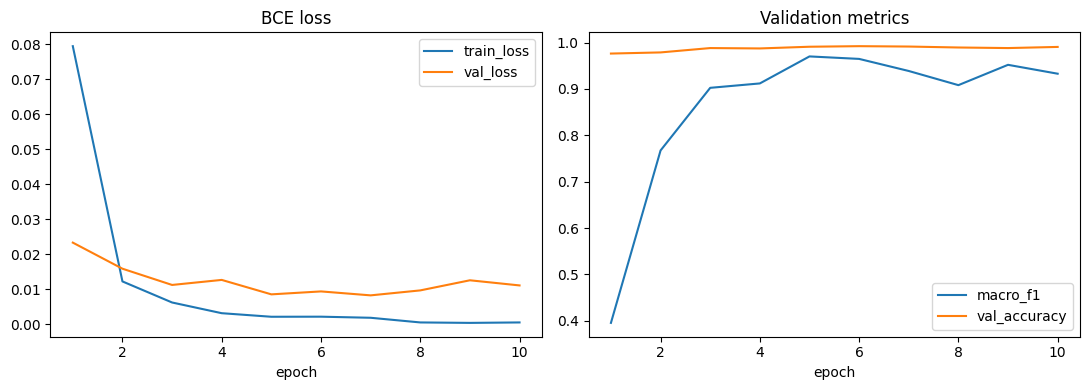

In [56]:
checkpoint = torch.load(BEST_PATH, map_location='cpu', weights_only=True)
assert checkpoint['config']['model_name'] == MODEL_NAME, 'Checkpoint model does not match MODEL_NAME.'
assert checkpoint['config']['label_cols'] == LABEL_COLS
model.load_state_dict(checkpoint['model'])
metrics, per_label, val_probabilities = validate()
val_targets = val_df[LABEL_COLS].to_numpy(dtype=np.int32)
metrics['val_accuracy'] = float(((val_probabilities >= THRESHOLD) == val_targets).all(axis=1).mean())
print('best epoch:', checkpoint['epoch'], '| metrics:', metrics)
display(per_label)
per_label.to_csv(OUTPUT_DIR / 'validation_metrics.csv')

val_predictions = val_df[['image_id', 'cluster', 'fold', *LABEL_COLS]].copy()
for j, label in enumerate(LABEL_COLS):
    val_predictions[f'{label}_prob'] = val_probabilities[:, j]
    val_predictions[f'{label}_pred'] = (val_probabilities[:, j] >= THRESHOLD).astype(np.int32)
val_predictions.to_csv(OUTPUT_DIR / 'validation_predictions.csv', index=False)

history_df = pd.DataFrame(history).set_index('epoch')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
history_df[['train_loss', 'val_loss']].plot(ax=axes[0], title='BCE loss')
history_df[['macro_f1', 'val_accuracy']].plot(ax=axes[1], title='Validation metrics')
plt.tight_layout()
plt.show()

## 7. Optional test inference and submission

Load the best checkpoint above, use the same deterministic transform and apply sigmoid.
Save probabilities separately; `submission.csv` contains binary predictions for macro F1.
The competition description requires the exact header `image_id,Cat,Dog,Moris,Motya,Biatrix`.
If present, `sample_submission.csv` defines row order; output columns always follow the competition header.

This section is skipped by default. Set `RUN_TEST_INFERENCE = True` after verifying the training result.

In [57]:
if RUN_TEST_INFERENCE:
    # Reload the best validation checkpoint; this does not retrain the model.
    test_checkpoint = torch.load(BEST_PATH, map_location='cpu', weights_only=True)
    assert test_checkpoint['config']['model_name'] == MODEL_NAME
    assert test_checkpoint['config']['label_cols'] == LABEL_COLS
    model.load_state_dict(test_checkpoint['model'])
    print('Test inference with best epoch:', test_checkpoint['epoch'])

    @torch.inference_mode()
    def predict_test():
        model.eval()
        probabilities = []
        for images in tqdm(test_loader, desc='test inference'):
            images = images.to(DEVICE, non_blocking=True)
            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                logits = model(images)
            probabilities.append(logits.float().sigmoid().cpu().numpy())
        return np.concatenate(probabilities)

    test_probabilities = predict_test()
    assert test_probabilities.shape == (len(test), len(LABEL_COLS))
    assert np.isfinite(test_probabilities).all()
    assert ((0 <= test_probabilities) & (test_probabilities <= 1)).all()
    probability_frame = pd.DataFrame(test_probabilities, columns=LABEL_COLS)
    probability_frame.insert(0, 'image_id', test.image_id.to_numpy())
    probability_frame.to_csv(OUTPUT_DIR / 'test_probabilities.csv', index=False)

    submission = probability_frame.copy()
    submission[LABEL_COLS] = (test_probabilities >= THRESHOLD).astype(np.int32)
    sample_path = DATA_DIR / 'sample_submission.csv'
    if sample_path.is_file():
        sample = pd.read_csv(sample_path, dtype={'image_id': str})
        assert set(sample.columns) == {'image_id', *LABEL_COLS}, 'Check the competition submission schema.'
        assert sample.image_id.notna().all() and sample.image_id.is_unique
        assert set(sample.image_id) == set(test.image_id), 'Sample IDs do not match test IDs.'
        submission = sample[['image_id']].merge(submission, on='image_id', how='left', validate='one_to_one')
    else:
        print('No sample_submission.csv found: using test.csv row order and the documented competition header.')
    submission = submission[['image_id', 'Cat', 'Dog', 'Moris', 'Motya', 'Biatrix']]
    assert len(submission) == len(test) and not submission.isna().any().any()
    assert submission[LABEL_COLS].isin([0, 1]).all().all()
    submission.to_csv(OUTPUT_DIR / 'submission.csv', index=False)
    print('saved:', OUTPUT_DIR / 'submission.csv')
    from IPython.display import FileLink
    display(FileLink(str(OUTPUT_DIR / 'submission.csv')))
    display(submission.head())
else:
    print('Test inference skipped. Training results are above in Evaluation.')

Test inference skipped. Training results are above in Evaluation.



References: [ImageNet-1k ConvNeXt-Tiny](https://huggingface.co/timm/convnext_tiny.fb_in1k),
[PyTorch CosineAnnealingLR](https://docs.pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.CosineAnnealingLR.html).